In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

In [26]:
df = sns.load_dataset('penguins')
df.head(300)
# 펭귄종, 서식지, "부리의 길이", 부리의 두께, 지느러미 길이, "몸무게", 성별

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
295,Gentoo,Biscoe,48.6,16.0,230.0,5800.0,Male
296,Gentoo,Biscoe,47.5,14.2,209.0,4600.0,Female
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male
298,Gentoo,Biscoe,45.2,13.8,215.0,4750.0,Female


In [ ]:
print(df.shape)   # 344개의 행(데이터), 7개의 열(속성)

(344, 7)


# Matplotlib 복습 :: scatter() 산점도
*   데이터 간의 관계 확인



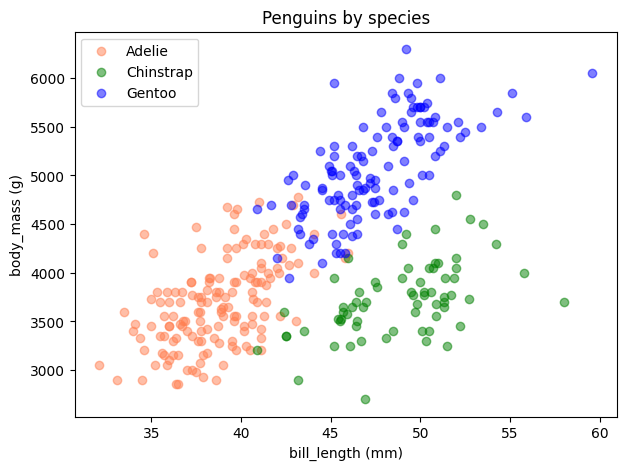

In [27]:
# 하나의 평면도에 여러 그래프 함께 그리기 :: 산점도 그래프
#  "3종류의 펭귄에 있어, 각 부리의 길이와 몸무게 산점도 표현"

# 전체 펭귄 데이터 중, 종의 이름이 'Adelie'인 데이터만 빼서 저장
adelie = df[df['species'] == 'Adelie']          # 152개 데이터
chinstrap = df[df['species'] == 'Chinstrap']    # 68개 데이터   -> 데이터 개수 적어서, 정확도 비교적 떨어짐
gentoo = df[df['species'] == 'Gentoo']          # 124개 데이터
# print(gentoo)

# 'Adelie'종의 부리의 길이(가로축)와 몸무게(세로축) 산점도 표현
plt.figure(figsize = (7, 5))
plt.scatter(adelie['bill_length_mm'], adelie['body_mass_g'],
            color='coral',alpha=0.5, label='Adelie')    # 'Adelie' 이름으로 라벨 붙임
plt.scatter(chinstrap['bill_length_mm'], chinstrap['body_mass_g'],
            color='green',alpha=0.5, label='Chinstrap')
plt.scatter(gentoo['bill_length_mm'], gentoo['body_mass_g'],
            color='blue',alpha=0.5, label='Gentoo')
plt.xlabel('bill_length (mm)')
plt.ylabel('body_mass (g)')
plt.title('Penguins by species')
plt.legend()    # 그래프의 라벨값 보여줌
plt.show()

# Adelie종은 대개 부리의 길이와 몸무게가 비교적 작은걸로 파악
# Chinstrap종은 대개 부리의 길이는 길되 몸무게가 작은걸로 파악
# Gentoo종은 대개 부리의 길이와 몸무게가 비교적 큰걸로 파악

# Matplotlib 복습 :: hist() 히스토그램


*   특정 데이터가 어느 구간에 많이 모였는지 파악



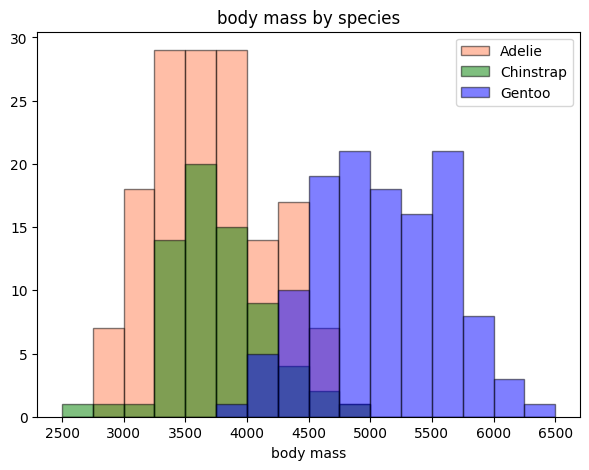

In [32]:
# 하나의 평면도에 여러 그래프 그리기 :: 히스토그램 그래프
# "3종류 펭귄의 몸무게 데이터 분포 표현"

plt.figure(figsize = (7, 5))

# 2500 ~6501 이전까지, 250 간격으로 값을 생성
bin_set = np.arange(2500, 6501, 250)

# 이쁘게 보이지 않는 이유 -> 2개 데이터의 데이터 범위 상이 -> 다른 범위를 데이터를 10개로 분할
#   => 영역을 동일하게 설정하면 이쁘게 겹쳐짐
plt.hist(adelie['body_mass_g'], bins=bin_set,
         color='coral', edgecolor='black', label='Adelie', alpha=0.5)
plt.hist(chinstrap['body_mass_g'], bins=bin_set,
         color='green', edgecolor='black', label='Chinstrap', alpha=0.5)
plt.hist(gentoo['body_mass_g'], bins=bin_set,
         color='blue', edgecolor='black', label='Gentoo', alpha=0.5)
plt.xlabel('body mass')
plt.title('body mass by species')
plt.legend()
plt.show()

# Adelie종 :: 3500g 내외의 영역에 주로 분포
# Chinstrap종 :: 3500g ~ 4000g 영역에 주로 분포
# Gentoo종 :: 4500g ~ 5000g 영역에 주로 분포

# Matplotlib 복습 :: bar() 막대그래프


*   값들 간의 비교



species
Adelie       38.791391
Chinstrap    48.833824
Gentoo       47.504878
Name: bill_length_mm, dtype: float64
species
Adelie       189.953642
Chinstrap    195.823529
Gentoo       217.186992
Name: flipper_length_mm, dtype: float64


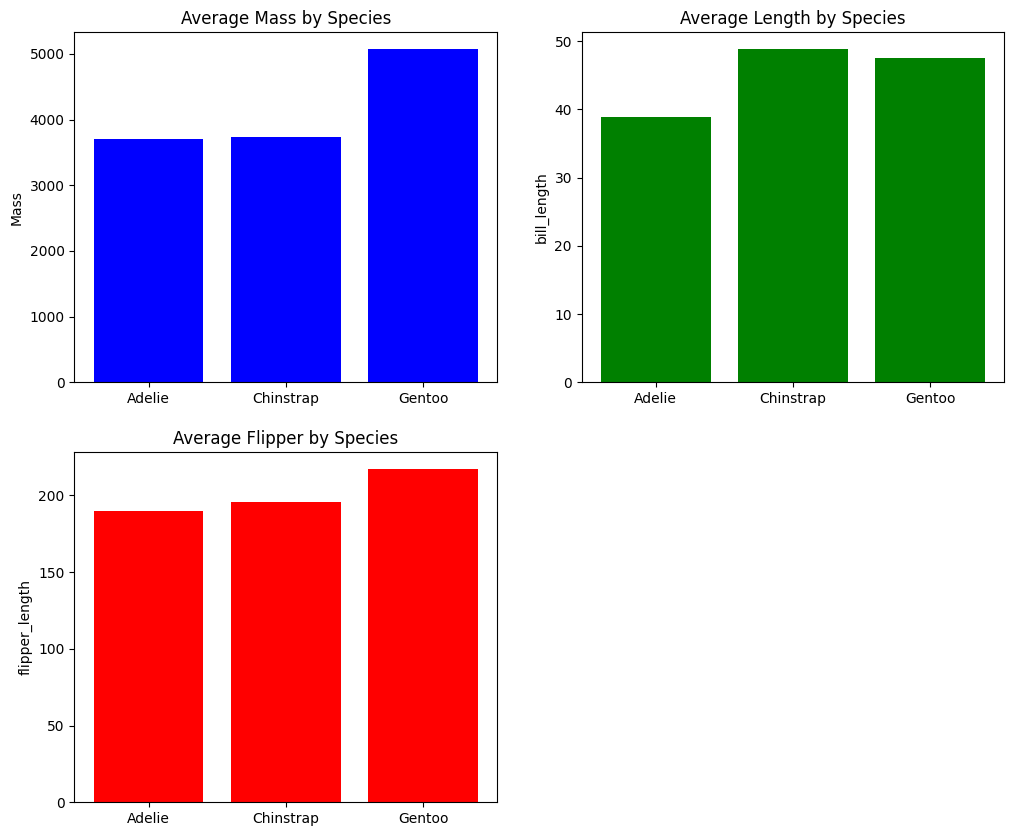

In [45]:
# 하나의 캔버스에 여러 평면도(그래프) 그리기 :: 막대 그래프
# "종별 평균 몸무게와 종별 평균 부리의 길이를 표현"

avg_mass = df.groupby('species')['body_mass_g'].mean()
# print(avg_mass)

plt.figure(figsize = (12, 10))

plt.subplot(2, 2, 1)      # subplot(몇번째 행의, 몇번째 열에 있어서, 요소 위치)
# 종별 평균 몸무게에 대한 막대그래프 구성
plt.bar(avg_mass.index, avg_mass.values, color='blue')
  # index = 'Adelie', 'Chinstrap', 'Gentoo'
  # value = 3700, 3733, 5076
plt.title('Average Mass by Species')
plt.ylabel('Mass')

avg_len = df.groupby('species')['bill_length_mm'].mean()
print(avg_len)

plt.subplot(2, 2, 2)
plt.bar(avg_len.index, avg_len.values, color='green')
plt.title('Average Length by Species')
plt.ylabel('bill_length')

# "Average Mass(파란색 그래프) 아래로", 제시하는 그래프 작성
# 지느러미 길이(flipper_length)의 종별 평균 막대그래프 작성
avg_fli = df.groupby('species')['flipper_length_mm'].mean()
print(avg_fli)
plt.subplot(2, 2, 3)
plt.bar(avg_fli.index, avg_fli.values, color='red')
plt.title('Average Flipper by Species')
plt.ylabel('flipper_length')

plt.show()